# Plausibility of the counterfactuals

For every counterfactual found, the mean Euclidean distance to the instances of the training
split, in the standardized feature space (`fig:plausability`). One run per loss and dataset:
synthetic-expert accuracy 0.75, seed 0, read from the validation cache (run `validation.ipynb`
first). The distances do not depend on the expert model. Outputs:
`figures/plausability_<loss>.pdf`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

import core

ACCURACY, SEED = 0.75, 0


def mean_distance(points, train, chunk=512):
    """Mean Euclidean distance from each point to all training instances."""
    return np.concatenate([cdist(points[i:i + chunk], train).mean(axis=1) for i in range(0, len(points), chunk)])


distances, rows = {}, []
for d in core.DATASETS:
    train = core.synthetic_task(d, ACCURACY, SEED)[1].data_train.tensors[0].numpy().astype(float)
    for m in core.METHODS:
        pairs, _ = core.load_run(core.validation_path(d, m, ACCURACY, SEED))
        pairs = pairs[pairs["found"]]
        distances[m, d] = mean_distance(core.points(pairs, "cf").astype(float), train)
        factual = mean_distance(core.points(pairs, "x").astype(float), train)
        rows.append(dict(method=m, dataset=d, n_counterfactuals=len(pairs), median_counterfactual=np.median(distances[m, d]),
                         median_deferred_point=np.median(factual)))
pd.DataFrame(rows).round(3)  # the deferred points themselves, as a reference

,method,dataset,n_counterfactuals,median_counterfactual,median_deferred_point
0,realizable_surrogate,adult,2069,4.230,4.206
1,crossentropy_surrogate,adult,5690,4.446,4.416
2,one_vs_all,adult,3228,4.329,4.314
3,realizable_surrogate,plant,800,2.444,2.418
4,crossentropy_surrogate,plant,1278,2.425,2.457
5,one_vs_all,plant,1138,2.511,2.493
6,realizable_surrogate,wine,147,4.023,4.042
7,crossentropy_surrogate,wine,190,4.058,4.081
8,one_vs_all,wine,115,4.047,4.039


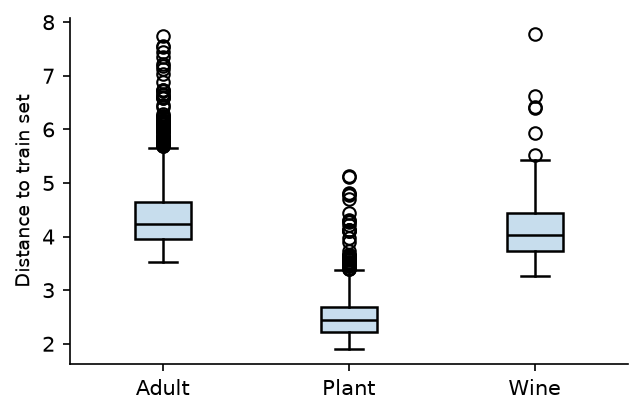

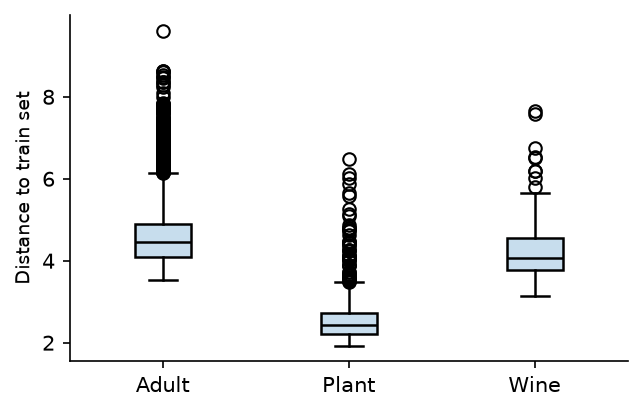

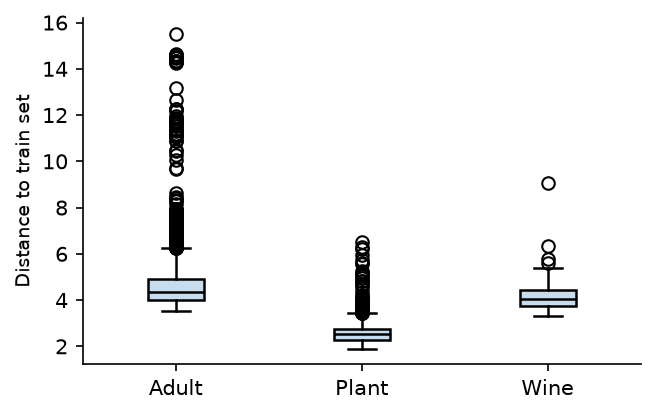

In [2]:
for m in core.METHODS:
    fig, ax = plt.subplots(figsize=(4.8, 3), dpi=150)
    box = ax.boxplot([distances[m, d] for d in core.DATASETS], patch_artist=True,
                     tick_labels=[core.DATASET_LABELS[d] for d in core.DATASETS])
    for patch in box["boxes"]:
        patch.set(facecolor="#C7DDED", alpha=1, edgecolor="black", linewidth=1.2)
    for element in ("whiskers", "caps", "medians", "fliers"):
        for item in box[element]:
            item.set(color="black", linewidth=1.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylabel("Distance to train set", fontsize=9)
    core.FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(core.FIGURES / f"plausability_{m}.pdf", bbox_inches="tight")
    plt.show()